In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem

In [2]:
visco = pd.read_csv('data/viscoelastic_expert_chen.csv', keep_default_na=False, na_values='')
visco.head()

,id_surfactant1,type_surfactant1,smiles_surfactant1,c_surfactant1,id_surfactant2,type_surfactant2,smiles_surfactant2,c_surfactant2,id_additive1,smiles_additive1,...,surfactant2_chen_BertzCT,surfactant2_chen_VSA_EState1,surfactant2_chen_MaxAbsEStateIndex,surfactant2_chen_Balaban,surfactant2_chen_SlogP_VSA2,surfactant2_chen_HallKierAlpha,surfactant2_chen_EState_VSA5,surfactant2_chen_MaxPartialCharge,surfactant2_chen_PEOE_VSA7,surfactant2_chen_PEOE_VSA8
0,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,295.628638,6.09324,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864
1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,295.628638,6.09324,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864
2,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,295.628638,6.09324,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864
3,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,295.628638,6.09324,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864
4,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,295.628638,6.09324,11.575318,3.274503,32.137605,-1.1,51.993423,0.307938,6.420822,19.3864


In [3]:
visco.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Data columns (total 63 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id_surfactant1                      8152 non-null   str    
 1   type_surfactant1                    8152 non-null   str    
 2   smiles_surfactant1                  8152 non-null   str    
 3   c_surfactant1                       8152 non-null   float64
 4   id_surfactant2                      8152 non-null   str    
 5   type_surfactant2                    8152 non-null   str    
 6   smiles_surfactant2                  8152 non-null   str    
 7   c_surfactant2                       2726 non-null   float64
 8   id_additive1                        8152 non-null   str    
 9   smiles_additive1                    8152 non-null   str    
 10  c_additive1                         5522 non-null   float64
 11  id_additive2                        8152 non-null   st

In [4]:
# numerical_columns = []
#
# for column in visco.columns:
#     if visco[column].dtype in ('float64', 'int64'):
#         numerical_columns.append(column)
#
# numerical_columns.remove('viscoelasticity')
#
# fig, axes = plt.subplots(12, 4, figsize=(20, 80))
# axes = axes.flatten()
#
# for ax, column in zip(axes, numerical_columns):
#     sns.boxplot(visco, ax=ax, x="viscoelasticity", y=column)

## Random forest

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import OneHotEncoder

In [58]:
y = visco['viscoelasticity']
drop_columns = [
    'viscoelasticity',
    'id_surfactant1',
    'smiles_surfactant1',
    'id_surfactant2',
    'smiles_surfactant2',
    'id_additive1',
    'smiles_additive1',
    'id_additive2',
    'smiles_additive2',
    'g_0',
    'g_min',
    'omega_cr',
    'tau_r',
    'eta_0'
]
X = visco.drop(drop_columns, axis=1)
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   type_surfactant1                    8152 non-null   str    
 1   c_surfactant1                       8152 non-null   float64
 2   type_surfactant2                    8152 non-null   str    
 3   c_surfactant2                       2726 non-null   float64
 4   c_additive1                         5522 non-null   float64
 5   c_additive2                         1333 non-null   float64
 6   temperature                         8152 non-null   int64  
 7   surfactant1_tail_length             8152 non-null   int64  
 8   surfactant2_tail_length             2631 non-null   float64
 9   surfactant1_mol_weight              8152 non-null   float64
 10  surfactant2_mol_weight              2631 non-null   float64
 11  surfactant1_chen_MolLogP            8152 non-null   fl

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [52]:
categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=5,
    min_samples_split=10
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

In [9]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](49,)","['type_surfactant1','c_surfactant1','type_surfactant2',..., 'surfactant2_chen_MaxPartialCharge','surfactant2_chen_PEOE_VSA7', 'surfactant2_chen_PEOE_VSA8']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,49
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifie

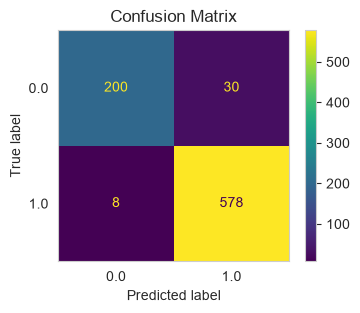

Accuracy: 0.9534313725490197


In [10]:
y_pred = model.predict(X_test)
fig, ax = plt.subplots(figsize=(4, 3))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=ax
)
ax.grid(False)
plt.title("Confusion Matrix")
plt.show()
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

## Standard StratifiedKFold

In [11]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

accs = []

for train_idx, test_idx in skf.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print("Accuracy:", acc)
    accs.append(acc)

mean_acc = np.mean(accs)
std_acc = np.std(accs, ddof=1)
print(f"Mean: {mean_acc:.4f}")
print(f"Std:   {std_acc:.4f}")

Accuracy: 0.9546568627450981
Accuracy: 0.9509803921568627
Accuracy: 0.9521472392638037
Accuracy: 0.939877300613497
Accuracy: 0.939877300613497
Accuracy: 0.9546012269938651
Accuracy: 0.9460122699386503
Accuracy: 0.9349693251533743
Accuracy: 0.9533742331288344
Accuracy: 0.9374233128834356
Mean: 0.9464
Std:   0.0077


## StratifiedGroupKFold

In [13]:
groups = visco[['id_surfactant1', 'id_surfactant2']].apply(tuple, axis=1)

accs = []

for seed in range(2):
    cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for train_idx, test_idx in cv.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ])

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        print("Accuracy:", acc)
        accs.append(acc)

mean_acc = np.mean(accs)
std_acc = np.std(accs, ddof=1)
print(f"Mean: {mean_acc:.4f}")
print(f"Std:   {std_acc:.4f}")

Accuracy: 0.9269289729177312
Accuracy: 0.7866323907455013
Accuracy: 0.8307475317348378
Accuracy: 0.41643454038997213
Accuracy: 0.7696709585121603
Accuracy: 0.7361751152073732
Accuracy: 0.46817691477885653
Accuracy: 0.6962962962962963
Accuracy: 0.7021276595744681
Accuracy: 0.8822170900692841
Accuracy: 0.9391926417986715
Accuracy: 0.7970660146699267
Accuracy: 0.847887323943662
Accuracy: 0.44906166219839144
Accuracy: 0.6749460043196545
Accuracy: 0.753120665742025
Accuracy: 0.7242302543507363
Accuracy: 0.746268656716418
Accuracy: 0.6282420749279539
Accuracy: 0.8723897911832946
Mean: 0.7324
Std:   0.1489


In [14]:
y.sum() / len(y)

np.float64(0.7154072620215898)

#### min_leaf=10 = 0.76
#### min_leaf=20 = 0.75

In [16]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

classifier = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

print(f"AUC: {roc_auc:.3f}")

AUC: 0.803


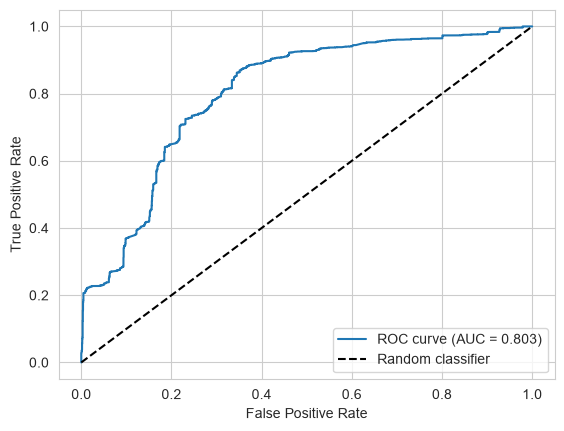

In [17]:
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [59]:
categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

cv = StratifiedGroupKFold(n_splits=10, shuffle=True)

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=5,
    min_samples_split=10
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

In [60]:
aucs = []
for _ in range(10):
    y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
    fpr, tpr, thresholds = roc_curve(y, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    print(f"AUC: {roc_auc:.3f}")

mean_auc = np.mean(aucs)
std_auc = np.std(aucs, ddof=1)
print(f"Mean: {mean_auc:.4f}")
print(f"Std:   {std_auc:.4f}")

AUC: 0.827
AUC: 0.809
AUC: 0.819
AUC: 0.805
AUC: 0.820
AUC: 0.828
AUC: 0.831
AUC: 0.826
AUC: 0.815
AUC: 0.832
Mean: 0.8213
Std:   0.0094


## Physiochemical features

In [33]:
physio = pd.read_csv('data/viscoelastic_physiochemical.csv', keep_default_na=False, na_values='')
physio.loc[len(physio)] = ['None'].extend(np.zeros(256))
physio.info()

<class 'pandas.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Columns: 257 entries, smiles to fp_255
dtypes: float64(256), object(1)
memory usage: 162.8+ KB


In [34]:
physio = physio.set_index('smiles')
merged = visco.join(physio.add_suffix('_1'), on='smiles_surfactant1', how='left')
merged = merged.join(physio.add_suffix('_2'), on='smiles_surfactant2', how='left')

In [35]:
merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Columns: 575 entries, id_surfactant1 to fp_255_2
dtypes: float64(563), int64(2), object(2), str(8)
memory usage: 35.8+ MB


In [41]:
merged.columns[:20]

Index(['id_surfactant1', 'type_surfactant1', 'smiles_surfactant1',
       'c_surfactant1', 'id_surfactant2', 'type_surfactant2',
       'smiles_surfactant2', 'c_surfactant2', 'id_additive1',
       'smiles_additive1', 'c_additive1', 'id_additive2', 'smiles_additive2',
       'c_additive2', 'temperature', 'viscoelasticity', 'g_0', 'g_min',
       'omega_cr', 'tau_r'],
      dtype='str')

In [61]:
y = merged['viscoelasticity']
X = merged.drop(drop_columns, axis=1)

In [57]:
groups = visco[['id_surfactant1', 'id_surfactant2']].apply(tuple, axis=1)

cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=41)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

In [49]:
y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

print(f"AUC: {roc_auc:.3f}")

AUC: 0.808


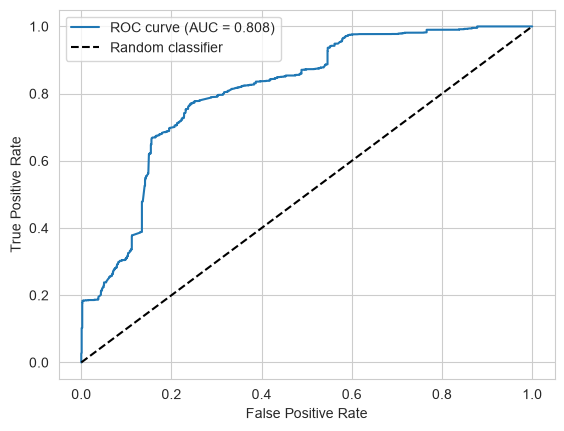

In [50]:
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [62]:
groups = visco[['id_surfactant1', 'id_surfactant2']].apply(tuple, axis=1)

cv = StratifiedGroupKFold(n_splits=10, shuffle=True)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=10,
    min_samples_split=20
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

In [63]:
aucs = []
for _ in range(10):
    y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
    fpr, tpr, thresholds = roc_curve(y, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    print(f"AUC: {roc_auc:.3f}")

mean_auc = np.mean(aucs)
std_auc = np.std(aucs, ddof=1)
print(f"Mean: {mean_auc:.4f}")
print(f"Std:   {std_auc:.4f}")

AUC: 0.809
AUC: 0.801
AUC: 0.807
AUC: 0.799
AUC: 0.810
AUC: 0.790
AUC: 0.793
AUC: 0.803
AUC: 0.804
AUC: 0.794
Mean: 0.8009
Std:   0.0070


# Zrobić dalex

In [18]:
#TODO